## Duck + NVFP4 + batch + stall warn + dead-signature ban

The policy cell installs two patches:

- `arc3_batch`: predict-then-commit. Patches both `prompts.PYTHON_ADDENDUM` and `tool_agent.PYTHON_ADDENDUM`. The built system prompt must contain `PREDICT-THEN-COMMIT`.
- `arc3_stall`: loop and grind detector with `MODE = "warn"`, plus a dead-signature ban. A stuck level adds `stuck_warning` to the action result. A signature that has already repeated until this level stopped advancing is dropped from later batches on this level. If every action left in the batch is banned, the original batch is returned unchanged. The batch is not replaced with RESET. This file does not issue RESET.

Parent public 25-game score of the warn behavior this file starts from: **3.37** (2026-09-20). This file has **no new 25-game score**. The stall print from that run was `resets_issued` 0, `resets_suppressed_invalid` 91, `warnings_shown` 91. The source string said `MODE=reset`; the valid-action gate suppressed every RESET, so the run was warn. This file says `MODE=warn`, does not issue RESET, and adds only the dead-signature ban.

Not RESET. Not ledger.

Serving stays `kv5-bf16-mtp3-c8-cg32` (prefix cache off, KV auto, 5368709120 bytes, MTP 3, max_seqs 8). `ONLY_RESET_LEVELS=true` stays. It does nothing while this policy never sends RESET.

Offline runs still integrity-check the 25 public ids, then play the 6-game depth probe (1 pass, 3600 s, concurrency 6). A 6-game mean is not a keep. A competition rerun still plays the live gateway (7920 s, concurrency 28).

The diagnostic cell still shows the 2026-09-20 probe print (`ARC3_RESET_RESULT`, mode reset, 0 RESET issued). That print is the record of that run.

### 2026-09-25 changes (score + budget fit)

- Prompt: adds the RHAE scoring rule (level score `(h/a)^2`, level weight = level index, uncleared = 0, RESET counts), a time line (points at `time_remaining_seconds` if the harness reports it, otherwise states the per-game budget), and a grid click-target line (only if the harness uses `current_frame` and `row`/`col`). Marker: `SCORING (how this run is graded)`.
- Budget: competition per-game budget 7920 s to 7750 s, then re-fitted before `bm.run` so all 4 waves (110 games at concurrency 28) finish before the soft end. Concurrency stays 28.
- Stall: ban behaviour unchanged. Adds observe-only counters `calls_single_action` and `calls_fully_banned_passthrough` to explain `actions_dropped` 0.
- Teardown: a teardown command that hangs past its 30 s timeout no longer raises.
- Serving profile unchanged (`kv5-bf16-mtp3-c8-cg32`).


# Tufa Labs ARC3 submission

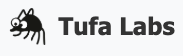

**Note**: this notebook is a more readable version of the notebook that scored our milestone-winning 1.21; unfortunately, we haven't had the same lucky result with this one. The original one is also shared here, but using it is not recommended: https://www.kaggle.com/code/jeroencottaar/taaf-duck-harness-kaggle

**Note**: if you make a copy of this notebook, you will have to manually select the proper GPU (RTX Pro 6000).

Link to writeup explaining what's going on here: https://www.kaggle.com/competitions/arc-prize-2026-arc-agi-3/discussion/717133

Link to Machine Learning Street Talk interview by Tim Scarfe about this duck harness: https://x.com/MLStreetTalk/status/2072326433922297975?s=20

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise.

## 1. Environment and submission mode

Detect whether this is a real competition rerun (which minimises diagnostics), set the
framework's environment flags, and put the CUDA libraries on the linker path.

In [ ]:
import json
import os
import pickle
import subprocess
import sys
import sysconfig
import time
from datetime import datetime, timedelta
from pathlib import Path
from urllib.request import urlopen

# True only inside a real competition rerun; switches diagnostics + soft deadline.
TRUE_SUBMISSION = os.environ.get("KAGGLE_IS_COMPETITION_RERUN", "").strip().lower() in {"1", "true"}
NOTEBOOK_START_EPOCH = time.time()

# Non-interactive matplotlib backend: diagnostics render plots with no display attached.
os.environ["MPLBACKEND"] = "Agg"
# Marks the run as a (real or emulated) submission so the framework + solver can adjust.
os.environ["TAAF_RUN_AS_SUBMISSION"] = "1" if TRUE_SUBMISSION else "0"
# Skip periodic JSON/HTML diagnostics and per-frame logging for every run.
os.environ["TAAF_MINIMAL_DIAGNOSTICS"] = "1"

# Apply the measured vLLM winner before any serving setup command runs.
PUBLIC25_VLLM_PROFILE_NAME = 'kv5-bf16-mtp3-c8-cg32'
PUBLIC25_VLLM_PROFILE_ENV = {
    "TAAF_VLLM_ENABLE_PREFIX_CACHING": "0",
    "TAAF_VLLM_KV_CACHE_DTYPE": "auto",
    "TAAF_VLLM_KV_CACHE_MEMORY_BYTES": "5368709120",
    "TAAF_VLLM_MAX_CUDAGRAPH_CAPTURE_SIZE": "32",
    "TAAF_VLLM_MAX_NUM_BATCHED_TOKENS": "8192",
    "TAAF_VLLM_MAX_NUM_SEQS": "8",
    "TAAF_VLLM_MTP_TOKENS": "3",
    "TAAF_VLLM_OMP_THREADS": "1"
}
for key, value in PUBLIC25_VLLM_PROFILE_ENV.items():
    os.environ[key] = value
print(
    f'PUBLIC25_VLLM_PROFILE name={PUBLIC25_VLLM_PROFILE_NAME} '
    f'env={json.dumps(PUBLIC25_VLLM_PROFILE_ENV, sort_keys=True)}',
    flush=True,
)
# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).
os.environ["ONLY_RESET_LEVELS"] = "true"

# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the
# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.
cuda_library_path = "/usr/local/nvidia/lib64"
os.environ["LIBRARY_PATH"] = os.pathsep.join(
    entry for entry in [cuda_library_path, *os.environ.get("LIBRARY_PATH", "").split(os.pathsep)] if entry
)

# Everything the run produces is written here.
WORKING_DIR = Path("/kaggle/working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}")

## 2. Install the ARC runtime

Install `arc-agi` from the offline competition wheelhouse (the Kaggle submission environment
has no internet).

In [ ]:
# Install the ARC runtime from the bundled competition wheels.
# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--no-index",
        "--no-warn-conflicts",
        "--disable-pip-version-check",
        "--find-links",
        "/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels",
        "arc-agi",
    ],
    stdout=subprocess.DEVNULL,
)

## 3. Locate the source bundle

Find the uploaded TAAF source dataset by its marker file, and record where Kaggle mounted
every attached input so setup commands and the solver can find them.

In [ ]:
# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.
DATASET_SOURCES = ["keithtyser/duck-qwen38-nvfp4-mtp-vllm-smoke-v1", "keithtyser/qwen38-flash-next-vllm-nvfp4-runtime-v1"]
KERNEL_SOURCES = []
DATASET_BUNDLE_MARKER = "taaf-kaggle-bundle.json"
SETUP_ENV_PATH = WORKING_DIR / "taaf_setup_env.json"


# Locate the source dataset by its marker file rather than a fixed mount path.
def _find_bundle_dir() -> Path:
    for marker in Path("/kaggle/input").rglob(DATASET_BUNDLE_MARKER):
        return marker.parent
    raise RuntimeError("TAAF source bundle not found under /kaggle/input.")


# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>
# (depending on owner / slug collisions), so probe both and use whichever exists. Utility
# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.
def _dataset_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/input") / slug, Path("/kaggle/input/datasets") / owner / slug]


def _kernel_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/usr/lib/notebooks") / owner / slug]


def _first_existing(candidates: list[Path]) -> Path | None:
    return next((c for c in candidates if c.exists()), None)


BUNDLE_DIR = _find_bundle_dir()
print(f"taaf.kaggle: source bundle = {BUNDLE_DIR}")

# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).
kaggle_input_paths: dict[str, str] = {}
for i, ref in enumerate(DATASET_SOURCES):
    candidates = _dataset_mount_candidates(ref)
    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)
    kaggle_input_paths[ref] = str(resolved or candidates[0])
for ref in KERNEL_SOURCES:
    candidates = _kernel_mount_candidates(ref)
    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])

# Published to setup commands and the solver via the environment:
setup_env = {
    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.
    "TAAF_KAGGLE_INPUT_PATHS": json.dumps(kaggle_input_paths, sort_keys=True),
    # The attached dataset refs in order (index 0 is this source bundle).
    "TAAF_KAGGLE_DATASET_SOURCES": json.dumps(DATASET_SOURCES),
    # The attached utility-script / kernel refs.
    "TAAF_KAGGLE_KERNEL_SOURCES": json.dumps(KERNEL_SOURCES),
}
os.environ.update(setup_env)
SETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + "\n")
print(f"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}")

## 4. Import the bundled source and run solver setup

Put the snapshotted repositories on the path (this process and any child processes), then run
the solver's setup commands â€” installing wheels, fetching model weights, and so on.

In [ ]:
# Each bundled repo exposes its importable tree at <repo>/src or <repo>.
def _source_path_entries(bundle_dir: Path) -> list:
    entries = []
    for repo in sorted((bundle_dir / "src").iterdir(), reverse=True):
        for candidate in (repo / "src", repo):
            if candidate.is_dir():
                entries.append(candidate)
    return entries


# Environment handed to each setup command (paths + any keys it has persisted).
def _command_env() -> dict:
    env = os.environ.copy()
    # "$PYTHON" in a command resolves to this notebook's interpreter.
    env["PYTHON"] = sys.executable
    # Absolute path to the mounted source bundle.
    env["TAAF_KAGGLE_BUNDLE_DIR"] = str(BUNDLE_DIR)
    # The writable /kaggle/working directory.
    env["TAAF_KAGGLE_WORKING_DIR"] = str(WORKING_DIR)
    # A command writes a JSON object here to persist env keys to later commands + the run.
    env["TAAF_KAGGLE_SETUP_ENV"] = str(SETUP_ENV_PATH)
    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})
    return env


# Make the bundled repos importable here (sys.path) and in child processes (.pth).
source_entries = _source_path_entries(BUNDLE_DIR)
for entry in source_entries:
    sys.path.insert(0, str(entry))
pth_path = Path(sysconfig.get_paths()["purelib"]) / "taaf_kaggle_sources.pth"
pth_path.write_text("".join(f"{entry}\n" for entry in source_entries))
print(f"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)")

# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.
env = _command_env()
for command in json.loads((BUNDLE_DIR / "setup_commands.json").read_text()):
    print(f"taaf.kaggle: setup command: {command}", flush=True)
    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)
    # Re-read in case the command persisted new env keys.
    env = _command_env()
    os.environ.update(env)

# Honour any PYTHONPATH a setup command exported.
for entry in reversed([e for e in os.environ.get("PYTHONPATH", "").split(os.pathsep) if e]):
    if entry not in sys.path:
        sys.path.insert(0, entry)

## 5. Load the benchmark

Unpickle the deployment target and the benchmark, stamping the real submission state onto the
target and pointing the benchmark's outputs at the Kaggle working directory.

In [ ]:
# Restore the deployment target and record the real submission state on it.
with open(BUNDLE_DIR / "deploy_target.pkl", "rb") as file:
    target = pickle.load(file)
target.actual_run_as_submission = TRUE_SUBMISSION
target.is_competition_rerun = TRUE_SUBMISSION

# Restore the benchmark and point its outputs at the Kaggle working dir.
with open(BUNDLE_DIR / "benchmark_initial.pkl", "rb") as file:
    bm = pickle.load(file)
bm.job_dir = WORKING_DIR

## 6. Customization hook

Optional: tweak `bm`, `bm.games`, or `bm.solver` here before the run starts â€” the safe place
for one-off experiments once the deployed bundle has loaded.

In [ ]:
# Exact public-25 and competition settings.
# arc3: 110 games at concurrency 28 run as 4 waves. At 7920 s that is 31680 s, about 600 s
# more than is left after setup (~725 s) and the 600 s soft-end reserve, so the last wave
# (~26 games) was cut short. 4 x 7750 = 31000 s fits. The run cell re-fits this to the real
# time left just before bm.run. A save run stays capped at 3600 s.
bm.solver.max_runtime_s_per_game = 7750.0 if TRUE_SUBMISSION else 3600.0
bm.solver.analyzer_timeout = 900.0
# arc3: the rerun keeps 28; the probe pins 6 so two passes run as two waves of six
# rather than twelve streams splitting one GPU, which would halve the per-game budget.
bm.solver.concurrency = 28 if TRUE_SUBMISSION else 6
bm.solver.max_actions_per_game = None
bm.solver.save_request_logs = False
if float(getattr(target, 'max_runtime_s', 0.0) or 0.0) != 32400.0:
    raise RuntimeError(
        f'Expected the 32400-second notebook budget, got {target.max_runtime_s!r}.'
    )
print(
    f'PUBLIC25_SETTINGS budget_s={bm.solver.max_runtime_s_per_game} '
    f'concurrency={bm.solver.concurrency} analyzer_timeout={bm.solver.analyzer_timeout} '
    f'action_cap={bm.solver.max_actions_per_game} request_logs={bm.solver.save_request_logs}',
    flush=True,
)


In [ ]:
# arc3_batch: prompt-only predict-then-commit batching. Nothing else is touched.
#
# tool_agent.py:17 does `from inference.agent.prompts import PYTHON_ADDENDUM`, so the
# value is bound into tool_agent's namespace at import time; patching prompts.py alone
# would be a silent no-op. arc3_batch patches both bindings and then asserts against the
# string _build_system_prompt actually returns, so a miss fails the cell, not the run.
ARC3_BATCH_SOURCE = "\"\"\"arc3_batch: predict-then-commit action batching, as a PROMPT-ONLY change.\n\nWhy this and nothing else (consult/research_2026-09-19_next_jump.md):\n  fp4run1 executed 2.33 actions per charged model decision, 57% of them singletons, at\n  802 generated tokens per executed action. The harness never truncates a batch\n  (stopped_early 0, known_noop 0), so the short batches are the model's own choice --\n  steered by two lines in prompts.py that pull against the one line encouraging batching.\n  Folding an extra action into an existing decision is nearly free, so 2.33 -> ~6 is\n  ~2.5x the actions per game from the same token budget.\n\nExternally corroborated: DREAMTEAM (NVIDIA, arXiv 2605.09650) runs max-actions-per-step\n= 20 behind a commit-then-retrodict gate and reports 54.1 actions per solved level against\na baseline's 100.1; Reki (Milestone-1 2nd) returns 1-4 actions per turn.\n\nTHE PATCH TARGET MATTERS. tool_agent.py:17 does `from inference.agent.prompts import\nPYTHON_ADDENDUM`, so the value is bound into tool_agent's namespace at import time and\n_build_system_prompt (tool_agent.py:499) resolves it as a tool_agent global at call time.\nPatching prompts.PYTHON_ADDENDUM alone is a silent no-op. We patch both and then assert\nagainst the real _build_system_prompt output.\n\nNo harness behaviour is touched: no new mechanism, no gating code, no counters. The only\nthing that changes is the system prompt text.\n\"\"\"\nfrom __future__ import annotations\n\n# --- the three exact lines we rewrite (each must appear exactly once) -----------------\n\nOLD_SHORTEST = (\n    \"- Optimize for the shortest reliable sequence that advances the current goal as \"\n    \"described by your world model. If confidence is low, program a discriminating probe \"\n    \"and revise the world model from the result.\\n\"\n)\nNEW_SHORTEST = (\n    \"- Optimize for the fewest WASTED actions, not the fewest actions per turn. A ten-action \"\n    \"plan you can predict is worth far more than one action you must re-derive next turn. If \"\n    \"confidence is low, program a discriminating probe and revise the world model from the result.\\n\"\n)\n\n# \"After EVERY action, verify\" is a literal instruction to end the turn after one action.\n# The HUD warning itself is a real correctness guard, so it is kept -- moved into the\n# definition of the signature you compare frames on, instead of being a reason to stop.\nOLD_HUD = (\n    \"- After every action, verify whether gameplay objects changed or whether only a timer, \"\n    \"progress bar, or remaining-step bar moved. Do not treat HUD-only changes as evidence \"\n    \"that the move worked.\\n\"\n)\nNEW_HUD = (\n    \"- When you check whether an action worked, ignore HUD-only changes: a timer, progress bar \"\n    \"or remaining-step bar moving is not evidence that the move affected gameplay. Exclude \"\n    \"those rows from any signature you compare frames on.\\n\"\n)\n\n# Anchor: the existing line that already licenses loops. The protocol goes right after it.\nANCHOR_LOOPS = (\n    \"- You can also call `action(...)` multiple times in one Python snippet, including inside \"\n    \"loops. Each call updates the preloaded variables before execution continues.\\n\"\n)\nPROTOCOL = (\n    \"- ACTION BUDGET: reaching one turn of reasoning costs you thousands of tokens; extra actions \"\n    \"inside that same turn cost almost nothing. A turn that executes a single action throws the \"\n    \"turn away. Once you know what the controls do, plan a sequence and commit it.\\n\"\n    \"- PREDICT-THEN-COMMIT: when your world model can predict what the next few actions will do, \"\n    \"execute them in one snippet behind a prediction gate:\\n\"\n    \"      def sig(f):   # cheap board signature; exclude HUD rows\\n\"\n    \"          ...\\n\"\n    \"      plan = [(a1, expected_sig_1), (a2, expected_sig_2), ...]\\n\"\n    \"      for i, (a, expected) in enumerate(plan):\\n\"\n    \"          action([a])\\n\"\n    \"          if last_action_result.get('level_completed') or last_action_result.get('game_over'):\\n\"\n    \"              break\\n\"\n    \"          if sig(current_frame) != expected:\\n\"\n    \"              print('mismatch at step', i, 'expected', expected, 'got', sig(current_frame))\\n\"\n    \"              break        # the world model was wrong: stop here and re-plan next turn\\n\"\n    \"  A mismatch is the most valuable thing the turn can produce, so report where it happened and \"\n    \"what differed. A gated plan is safe: it stops itself the moment reality diverges.\\n\"\n    \"- Aim for 5-15 actions per turn once the controls are understood. Spend one- or two-action \"\n    \"turns only while you are still identifying what the controls do.\\n\"\n)\n\n\ndef build_addendum(current: str) -> str:\n    \"\"\"Apply the three edits to PYTHON_ADDENDUM, failing loudly on upstream drift.\"\"\"\n    for name, old in ((\"OLD_SHORTEST\", OLD_SHORTEST), (\"OLD_HUD\", OLD_HUD),\n                      (\"ANCHOR_LOOPS\", ANCHOR_LOOPS)):\n        n = current.count(old)\n        if n != 1:\n            raise RuntimeError(f\"arc3_batch: expected {name} exactly once in PYTHON_ADDENDUM, found {n}\")\n    out = current.replace(OLD_SHORTEST, NEW_SHORTEST)\n    out = out.replace(OLD_HUD, NEW_HUD)\n    out = out.replace(ANCHOR_LOOPS, ANCHOR_LOOPS + PROTOCOL)\n    return out\n\n\nMARKER = \"PREDICT-THEN-COMMIT\"\n\n\ndef install() -> dict:\n    \"\"\"Patch the system prompt in place. Idempotent; verifies against _build_system_prompt.\"\"\"\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    if MARKER in TA.PYTHON_ADDENDUM:\n        return {\"installed\": \"already\"}\n\n    before = len(TA.PYTHON_ADDENDUM)\n    new = build_addendum(TA.PYTHON_ADDENDUM)\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n\n    # The only proof that matters: the prompt the agent actually sends.\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if MARKER not in built:\n        raise RuntimeError(\"arc3_batch: patch did not reach _build_system_prompt\")\n    for name, old in ((\"OLD_SHORTEST\", OLD_SHORTEST), (\"OLD_HUD\", OLD_HUD)):\n        if old in built:\n            raise RuntimeError(f\"arc3_batch: {name} still present in the built system prompt\")\n    return {\n        \"installed\": True,\n        \"addendum_chars\": len(new),\n        \"delta_chars\": len(new) - before,\n        \"system_prompt_chars\": len(built),\n    }\n"
Path('/kaggle/working/arc3_batch.py').write_text(ARC3_BATCH_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')

import importlib
import arc3_batch
arc3_batch = importlib.reload(arc3_batch)
print('arc3_batch:', arc3_batch.install(), flush=True)

from inference.agent import tool_agent as _ta
_built = _ta._build_system_prompt(tool_output_tokens=1024)
assert arc3_batch.MARKER in _built, 'arc3_batch did not reach the system prompt'
print('ARC3_BATCH_PROMPT chars=%d marker=%s' % (len(_built), arc3_batch.MARKER), flush=True)

# arc3_stall: loop/grind detector on top of arc3_batch. MODE is warn.
# A stuck level adds stuck_warning. Dead signatures are dropped from later batches.
# This file does not issue RESET.
ARC3_STALL_SOURCE = "\"\"\"arc3_stall: tell the agent when it is looping on a level it cannot clear.\n\nEvidence (depthrun1, 6 games x 3600 s). Duck clears every level it clears at or better\nthan human pace, then hits ONE level and grinds without ever clearing it -- 1.4-7.2x the\nhuman baseline, all six games ending `gave_up` still on that level. On the wall level the\naction mix collapses:\n\n    game  cleared-levels uniq_frac -> wall uniq_frac   most-repeated action on the wall\n    sb26            0.67 -> 0.16                       one click x19  of 133\n    vc33            0.24 -> 0.10                       one click x122 of 439\n    lp85            0.29 -> 0.12                       one click x30  of 83\n    re86            0.05 -> 0.02                       ACTION3  x104 of 368\n    ft09            0.67 -> 0.41\n\nvc33 clicked the same cell 122 times. That is a loop, and Duck's own no-op guard cannot\nsee it: the guard only blocks an action that left the board UNCHANGED in that exact state,\nand a looping action usually does change the board (it just changes it pointlessly, or\noscillates). Nothing anywhere else in the harness notices.\n\nMODE is warn. A stuck level adds stuck_warning to the result the model reads. The batch\nis not replaced, and this module does not issue RESET.\n\nDead-signature ban: once reason() is non-empty, a signature that has occurred REPEAT_N\ntimes on this level, or the dominant signature behind that reason, is dropped from\nbatches on this level. The ban clears when the level index changes. RESET and ACTION7\nare never dropped. If every action in a batch is banned, that batch is returned unchanged.\n\nstallrun2 ran warn over the same 6 games: 100 warnings, normalised loop metric 0.234 to\n0.219, levels 19 to 23, and that +4 was entirely sb26 going 1 to 7. Without sb26 that\n6-game mean was 23.33 vs 28.81, with 42% more actions. A 6-game table is not a keep.\nThe public 25-game number for this warn behavior is 3.37 (2026-09-20). The source on that\nrun said MODE=reset, and the print was resets_issued 0, resets_suppressed_invalid 91,\nwarnings_shown 91: the valid-action gate suppressed every RESET, so the run was warn.\nRemoving the gate and issuing RESET scored 2.84. Do not put a batch-replacing RESET back\ninto this file.\n\nBASELINE-FREE BY CONSTRUCTION. base_actions_per_level is None in submission mode\n(game_api.py:232-242), so nothing may compare against the human baseline -- it works on the\n25 public games and silently dies on the hidden set. The grind trigger therefore compares\nthe current level against the median of THAT GAME'S OWN cleared levels. depthrun1 shows the\nseparation is wide: cleared levels ran 4-80 actions, wall levels 83-439.\n\nHooks, and READ THIS BEFORE EDITING. The Kaggle FP4 stack does NOT ship the Duck revision\nin duck-study/taaf. Its bundle (keithtyser/duck-qwen38-nvfp4-mtp-vllm-smoke-v1, dated\n2026-08-31) carries an EARLIER tool_agent.py -- 89,299 bytes against the 108,927 in taaf --\nwith **no noop_guard.py at all**, no `_aggregate_action_batch_result`, and no per-action\nbatch walk: one `action([...])` call is one atomic step_env call. A first version of this\nmodule hooked `NoopGuard.observe` and died on Kaggle with\n`ImportError: cannot import name 'noop_guard' from 'inference.agent'` after 11 minutes of\nsetup. Pre-flight against duck-study/fp4src/ARC3-Inference, which is the shipped source.\n\nBoth hooks are plain methods on ToolAgent, and one ToolAgent plays one game, so per-instance\nstate is per-game state:\n  ToolAgent._normalize_python_actions  -> observe the request, ban dead signatures, drop them\n  ToolAgent._compact_action_result     -> stuck_warning, plus the signatures dropped this call\n`_serialized_runtime_state` and `_handle_action` are CLOSURES inside a method\n(tool_agent.py:1466, :1495 in the shipped file) and cannot be patched from outside.\n\"\"\"\nfrom __future__ import annotations\n\nimport os\nimport statistics\n\nREPEAT_N = int(os.environ.get(\"ARC3_STALL_REPEAT_N\", \"10\"))    # same action this often on one level\nWINDOW = int(os.environ.get(\"ARC3_STALL_WINDOW\", \"40\"))        # rolling window for the mix check\nUNIQ_FRAC = float(os.environ.get(\"ARC3_STALL_UNIQ_FRAC\", \"0.2\"))\nGRIND_MULT = float(os.environ.get(\"ARC3_STALL_GRIND_MULT\", \"3.0\"))\nGRIND_FLOOR = int(os.environ.get(\"ARC3_STALL_GRIND_FLOOR\", \"60\"))\nRENOTIFY_EVERY = int(os.environ.get(\"ARC3_STALL_RENOTIFY\", \"15\"))\n\n# Arming gate, applied to EVERY trigger. Without it the repeat rule fires during healthy\n# play on movement games, where pressing ACTION3 ten times in a row is just walking: the\n# depthrun1 replay warned re86 at action 13 and ar25 at 16 of levels they went on to CLEAR.\n# A warning that interrupts a working plan is worse than a late one, so nothing fires until\n# the level has already cost 3x this game's own cleared levels. At 2.0 the replay still\n# warned inside ar25's level 3 (80 actions against a median of 28) and vc33's level 3,\n# both of which were then CLEARED. 3.0 costs us the ar25 wall entirely and is still the\n# right trade: a late warning wastes actions, a wrong one derails a level being solved.\nMIN_ON_LEVEL = int(os.environ.get(\"ARC3_STALL_MIN_ON_LEVEL\", \"45\"))\n# Warn only. ARC3_STALL_MODE is intentionally not read: a shell export must not\n# turn this file back into a firing reset. The 3.37 public run issued 0 RESET.\nMODE = \"warn\"\nassert MODE == \"warn\"\nARM_MULT = float(os.environ.get(\"ARC3_STALL_ARM_MULT\", \"3.0\"))\n\nSTATS = {\"levels_seen\": 0, \"trips\": 0, \"warnings_shown\": 0,\n         \"bans_armed\": 0, \"actions_dropped\": 0}\n\nclass _Tracker:\n    \"\"\"Per-ToolAgent state, and one ToolAgent plays one game.\"\"\"\n\n    def __init__(self) -> None:\n        self.level = None\n        self.counts: dict[str, int] = {}\n        self.window: list[str] = []\n        self.on_level = 0\n        self.cleared: list[int] = []      # actions spent on each level this game CLEARED\n        self.warned_at = 0\n        self.banned: set[str] = set()\n        self.dropped: list[str] = []\n\n    def _new_level(self, level) -> None:\n        if self.level is not None and self.on_level > 0:\n            # the level advanced, so the previous one was cleared\n            self.cleared.append(self.on_level)\n        self.level = level\n        self.counts = {}\n        self.window = []\n        self.on_level = 0\n        self.warned_at = 0\n        self.banned = set()\n        self.dropped = []\n        STATS[\"levels_seen\"] += 1\n\n    def note_level(self, level) -> None:\n        # First concrete level keeps counts already stored while level was still unknown.\n        if level is None or level == self.level:\n            return\n        if self.level is None:\n            self.level = level\n            STATS[\"levels_seen\"] += 1\n            return\n        self._new_level(level)\n\n    def observe(self, level, action_sig: str) -> None:\n        if level != self.level:\n            self._new_level(level)\n        self.on_level += 1\n        self.counts[action_sig] = self.counts.get(action_sig, 0) + 1\n        self.window.append(action_sig)\n        if len(self.window) > WINDOW:\n            del self.window[0]\n\n    def _dominant(self) -> \"tuple[str, int]\":\n        worst_sig, worst_n = \"\", 0\n        for sig, n in self.counts.items():\n            if n > worst_n:\n                worst_sig, worst_n = sig, n\n        return worst_sig, worst_n\n\n    def reason(self) -> str:\n        \"\"\"Why this level looks stuck, or \"\". Pure: no counters, no state.\"\"\"\n        arm = MIN_ON_LEVEL\n        if self.cleared:\n            arm = max(arm, ARM_MULT * statistics.median(self.cleared))\n        if self.on_level < arm:\n            return \"\"\n\n        worst_sig, worst_n = self._dominant()\n\n        if worst_n >= REPEAT_N:\n            return f\"you have executed {worst_sig} {worst_n} times on this level\"\n        if len(self.window) >= WINDOW and len(set(self.window)) / len(self.window) < UNIQ_FRAC:\n            return (f\"your last {len(self.window)} actions used only \"\n                    f\"{len(set(self.window))} distinct actions\")\n        if self.cleared:\n            budget = max(GRIND_FLOOR, GRIND_MULT * statistics.median(self.cleared))\n            if self.on_level >= budget:\n                return (f\"you have spent {self.on_level} actions on this level, against a median \"\n                        f\"of {statistics.median(self.cleared):.0f} on the levels you already cleared\")\n        elif self.on_level >= max(GRIND_FLOOR, REPEAT_N * 6):\n            return f\"you have spent {self.on_level} actions on this level without clearing it\"\n        return \"\"\n\n    def consider_bans(self) -> None:\n        \"\"\"Mark dead signatures on this level. Never bans RESET or ACTION7.\"\"\"\n        if not self.reason():\n            return\n        worst_sig, _worst_n = self._dominant()\n        for sig, n in self.counts.items():\n            if not sig or _never_ban(sig):\n                continue\n            # reason() is already non-empty, and the level index has not moved:\n            # counts and banned are cleared in _new_level.\n            if n >= REPEAT_N or sig == worst_sig:\n                if sig not in self.banned:\n                    self.banned.add(sig)\n                    STATS[\"bans_armed\"] += 1\n\n    def armed(self) -> str:\n        \"\"\"reason(), rate-limited to once every RENOTIFY_EVERY actions on this level.\"\"\"\n        r = self.reason()\n        if not r:\n            return \"\"\n        if self.warned_at and self.on_level - self.warned_at < RENOTIFY_EVERY:\n            return \"\"\n        self.warned_at = self.on_level\n        STATS[\"trips\"] += 1\n        return r\n\n    def warning(self) -> \"str | None\":\n        r = self.armed()\n        if not r:\n            return None\n        STATS[\"warnings_shown\"] += 1\n        return (\n            f\"STUCK: {r}, and the level has not advanced. Repeating it again will not clear \"\n            \"the level. Your current hypothesis about this level is wrong. Stop executing the plan \"\n            \"you are on, re-read the board from scratch, and form a DIFFERENT hypothesis about what \"\n            \"this level wants -- a different object to act on, a different mechanic, or a different \"\n            \"goal than the one you assumed.\"\n        )\n\n\n_ORIG_NORMALIZE = None\n_ORIG_COMPACT = None\n\n\ndef _tracker(agent) -> \"_Tracker\":\n    t = getattr(agent, \"_arc3_tracker\", None)\n    if t is None:\n        t = _Tracker()\n        try:\n            agent._arc3_tracker = t\n        except Exception:\n            pass\n    return t\n\n\ndef _sig(action) -> str:\n    \"\"\"Signature of one action. Handles BOTH shapes: the tool_agent normalized form\n    {\"action\": NAME, \"row\": r, \"col\": c} (Duck speaks row/col and raises on x/y), and the\n    engine/benchmark form {\"id\": NAME, \"data\": {\"x\": .., \"y\": ..}} used by replays. Getting\n    this wrong collapses every click to one signature and fires the repeat rule on healthy\n    play -- the pre-flight caught exactly that.\n    \"\"\"\n    if not isinstance(action, dict):\n        return str(action)\n    name = str(action.get(\"action\") or action.get(\"id\") or \"?\")\n    if \"row\" in action or \"col\" in action:\n        return f\"{name}:{action.get('row')},{action.get('col')}\"\n    data = action.get(\"data\")\n    if isinstance(data, dict) and data:\n        return f\"{name}:{data.get('x')},{data.get('y')}\"\n    return name\n\n\ndef _never_ban(sig: str) -> bool:\n    name = str(sig).split(\":\", 1)[0]\n    return name in (\"RESET\", \"ACTION7\")\n\n\ndef _level_for(agent, tracker: \"_Tracker\"):\n    last = getattr(agent, \"_last_action_result\", None)\n    if isinstance(last, dict) and last.get(\"level\") is not None:\n        return last.get(\"level\")\n    return tracker.level\n\n\ndef _ban_sentence(sigs: list[str]) -> str:\n    shown = \", \".join(sigs)\n    return (\n        \"banned this level: \"\n        + shown\n        + \" — it was repeated until the level stopped advancing; \"\n        \"do not emit it again on this level; pick a different action.\"\n    )\n\n\ndef install() -> dict:\n    \"\"\"Patch the two ToolAgent methods the shipped revision actually has. Idempotent.\"\"\"\n    global _ORIG_NORMALIZE, _ORIG_COMPACT\n    if MODE != \"warn\":\n        raise RuntimeError(\"arc3_stall: MODE must be warn; this file does not issue RESET\")\n    from inference.agent import tool_agent as TA\n\n    if getattr(TA.ToolAgent._compact_action_result, \"_arc3_stall\", False):\n        return {\"installed\": \"already\"}\n\n    _ORIG_NORMALIZE = TA.ToolAgent._normalize_python_actions\n    _ORIG_COMPACT = TA.ToolAgent._compact_action_result\n\n    def normalize(self, value):\n        out = _ORIG_NORMALIZE(self, value)\n        try:\n            actions = list(out) if isinstance(out, list) else []\n            t = _tracker(self)\n            t.dropped = []\n            level = _level_for(self, t)\n            for action in actions:\n                t.observe(level, _sig(action))\n            t.consider_bans()\n            kept = []\n            dropped = []\n            for action in actions:\n                sig = _sig(action)\n                if _never_ban(sig) or sig not in t.banned:\n                    kept.append(action)\n                else:\n                    dropped.append(action)\n            sigs = []\n            for action in dropped:\n                sig = _sig(action)\n                if sig not in sigs:\n                    sigs.append(sig)\n            t.dropped = sigs\n            # An empty filtered batch is returned unchanged. Do not invent an action.\n            if not kept:\n                return out\n            STATS[\"actions_dropped\"] += len(dropped)\n            return kept\n        except Exception:\n            return out\n\n    normalize._arc3_stall = True\n    TA.ToolAgent._normalize_python_actions = normalize\n\n    def compact(self, payload):\n        out = _ORIG_COMPACT(self, payload)\n        try:\n            if not isinstance(out, dict):\n                return out\n            t = _tracker(self)\n            new_level = out.get(\"level\")\n            advanced = (\n                bool(out.get(\"executed\"))\n                and new_level is not None\n                and t.level is not None\n                and new_level != t.level\n            )\n            dropped = [] if advanced else list(t.dropped or [])\n            t.dropped = []\n            msg = None\n            if out.get(\"executed\") and not advanced:\n                msg = t.warning()\n            if dropped:\n                extra = _ban_sentence(dropped)\n                msg = (msg + \" \" + extra) if msg else extra\n            if msg:\n                out[\"stuck_warning\"] = msg\n            if out.get(\"executed\"):\n                t.note_level(new_level)\n        except Exception:\n            pass   # a counter must never break a run\n        return out\n\n    compact._arc3_stall = True\n    TA.ToolAgent._compact_action_result = compact\n    return {\"installed\": True, \"mode\": MODE,\n            \"repeat_n\": REPEAT_N, \"window\": WINDOW, \"uniq_frac\": UNIQ_FRAC,\n            \"grind_mult\": GRIND_MULT, \"grind_floor\": GRIND_FLOOR,\n            \"min_on_level\": MIN_ON_LEVEL, \"arm_mult\": ARM_MULT,\n            \"bans_armed\": STATS[\"bans_armed\"], \"actions_dropped\": STATS[\"actions_dropped\"]}\n\n\n_BANNED_ACTION_SENTENCE = (\n    \"If a warning lists a banned action, do not emit that same action again on this level.\"\n)\n\nPROMPT_LINE = (\n    \"- `last_action_result` may carry a `stuck_warning` from the runner. It means this level has \"\n    \"already cost far more actions than the levels you cleared, and that you have been repeating \"\n    \"yourself. Treat it as decisive: your hypothesis about this level is wrong. \"\n    \"Re-read the board from scratch and form a different hypothesis about what the level wants \"\n    \"before acting again. \"\n    + _BANNED_ACTION_SENTENCE\n    + \"\\n\"\n)\n\n\ndef install_prompt() -> dict:\n    \"\"\"Tell the model what a stuck_warning means. Same binding trap as arc3_batch.\"\"\"\n    from inference.agent import prompts as P\n    from inference.agent import tool_agent as TA\n\n    have_stuck = \"stuck_warning\" in TA.PYTHON_ADDENDUM\n    have_ban = _BANNED_ACTION_SENTENCE in TA.PYTHON_ADDENDUM\n    if have_stuck and have_ban:\n        return {\"installed\": \"already\"}\n    extra = \"\"\n    if not have_stuck:\n        extra += PROMPT_LINE\n    elif not have_ban:\n        extra += _BANNED_ACTION_SENTENCE + \"\\n\"\n    new = TA.PYTHON_ADDENDUM + extra\n    TA.PYTHON_ADDENDUM = new\n    P.PYTHON_ADDENDUM = new\n    built = TA._build_system_prompt(tool_output_tokens=1024)\n    if \"stuck_warning\" not in built:\n        raise RuntimeError(\"arc3_stall: prompt line did not reach _build_system_prompt\")\n    if \"PREDICT-THEN-COMMIT\" not in built:\n        raise RuntimeError(\"arc3_stall: PREDICT-THEN-COMMIT lost from _build_system_prompt\")\n    if _BANNED_ACTION_SENTENCE not in built:\n        raise RuntimeError(\"arc3_stall: banned-action sentence did not reach _build_system_prompt\")\n    return {\"installed\": True}\n"
Path('/kaggle/working/arc3_stall.py').write_text(ARC3_STALL_SOURCE, encoding='utf-8')
if '/kaggle/working' not in sys.path:
    sys.path.insert(0, '/kaggle/working')
# /kaggle/working was already on sys.path from the arc3_batch cell, so its FileFinder has a
# cached directory listing that predates this write. Without this, `import arc3_stall` raises
# ModuleNotFoundError for a file that is sitting right there -- it did, on reset run v1.
importlib.invalidate_caches()

import arc3_stall
arc3_stall = importlib.reload(arc3_stall)
assert arc3_stall.MODE == 'warn', 'arc3_stall must run in warn mode'
print('arc3_stall:', arc3_stall.install(), flush=True)
print('arc3_stall prompt:', arc3_stall.install_prompt(), flush=True)

_built2 = _ta._build_system_prompt(tool_output_tokens=1024)
assert 'stuck_warning' in _built2, 'arc3_stall prompt line did not reach the system prompt'
assert arc3_batch.MARKER in _built2, 'arc3_batch protocol lost'
print('ARC3_STALL_READY chars=%d' % len(_built2), flush=True)
_BANNED_PROMPT = (
    'WHEN AN ATTEMPT FAILS',
    'SELECT THEN PLACE',
    'PATH BEFORE READING ORDER',
    'CENTER MAP',
    'arc3_ledger',
    'arc3_select',
    'arc3_path',
    'arc3_map',
)
for _banned in _BANNED_PROMPT:
    assert _banned not in _built2, _banned
    assert _banned not in ARC3_STALL_SOURCE, _banned
    assert _banned not in ARC3_BATCH_SOURCE, _banned
assert '_maybe_reset' not in ARC3_STALL_SOURCE
assert not hasattr(arc3_stall, '_maybe_reset')
assert 'resets_issued' not in arc3_stall.STATS
assert '[{"action": "RESET"}]' not in ARC3_STALL_SOURCE
assert 'If a warning lists a banned action, do not emit that same action again on this level.' in _built2
assert 'banned this level' in ARC3_STALL_SOURCE
assert 'level was RESET' not in ARC3_STALL_SOURCE
assert 'bans_armed' in arc3_stall.STATS
assert 'actions_dropped' in arc3_stall.STATS
assert arc3_stall.MODE == 'warn'
assert arc3_stall.ARM_MULT >= 3.0
assert arc3_stall.MIN_ON_LEVEL >= 45
_EXPECTED_PROFILE = {
    "TAAF_VLLM_ENABLE_PREFIX_CACHING": "0",
    "TAAF_VLLM_KV_CACHE_DTYPE": "auto",
    "TAAF_VLLM_KV_CACHE_MEMORY_BYTES": "5368709120",
    "TAAF_VLLM_MAX_CUDAGRAPH_CAPTURE_SIZE": "32",
    "TAAF_VLLM_MAX_NUM_BATCHED_TOKENS": "8192",
    "TAAF_VLLM_MAX_NUM_SEQS": "8",
    "TAAF_VLLM_MTP_TOKENS": "3",
    "TAAF_VLLM_OMP_THREADS": "1",
}
assert PUBLIC25_VLLM_PROFILE_NAME == 'kv5-bf16-mtp3-c8-cg32'
assert PUBLIC25_VLLM_PROFILE_ENV == _EXPECTED_PROFILE
for _k, _v in _EXPECTED_PROFILE.items():
    assert os.environ.get(_k) == _v, (_k, os.environ.get(_k))
assert os.environ.get('ONLY_RESET_LEVELS') == 'true'
assert isinstance(TRUE_SUBMISSION, bool)
print(
    'ARC3_POLICY mode=%s dead_signature=on reset_injector=absent ledger=absent profile=%s only_reset_levels=%s'
    % (arc3_stall.MODE, PUBLIC25_VLLM_PROFILE_NAME, os.environ.get('ONLY_RESET_LEVELS')),
    flush=True,
)


# arc3_score (2026-09-25): scoring, time and click-target lines. Prompt-only, with the same
# binding trap as arc3_batch: patch both PYTHON_ADDENDUM bindings, then assert on the prompt
# _build_system_prompt actually returns. Evidence: disc/743060 went 1.12 -> 1.43 on the hidden
# set with a scoring-formula line plus a time_remaining_seconds pacing line. Formula per
# docs.arcprize.org/methodology (level weight = level index; RESET counts as an action).
import re as _re

_inference_root = Path(_ta.__file__).resolve().parents[1]
_inference_src = "\n".join(
    _p.read_text(encoding="utf-8", errors="replace") for _p in sorted(_inference_root.rglob("*.py"))
)
# Point at the live clock only if this bundle's harness reports it; otherwise state the budget.
ARC3_HAS_TIME_FIELD = "time_remaining_seconds" in _inference_src
# Add the click hint only if the harness itself uses these names.
ARC3_HAS_GRID_NAMES = (
    "current_frame" in _inference_src
    and _re.search(r"""['"]row['"]""", _inference_src) is not None
    and _re.search(r"""['"]col['"]""", _inference_src) is not None
)

ARC3_SCORE_MARKER = "SCORING (how this run is graded)"
ARC3_SCORE_LINE = (
    "- " + ARC3_SCORE_MARKER + ": each level you CLEAR scores (h / a)^2, where h is the number "
    "of actions a first-time human needed on that level and a is the number you used. Every action "
    "counts, including RESET. Level k carries weight k: in a 7-level game level 7 is worth 7/28 of "
    "the game and level 1 only 1/28. A level you do not clear scores 0. Clearing a level at twice "
    "the human's actions still keeps 1/4 of its value; not clearing it keeps nothing. So never "
    "explore less to save actions: save actions by never repeating an action or plan that already "
    "failed.\n"
)
if ARC3_HAS_TIME_FIELD:
    _arc3_clock = "Action results report `time_remaining_seconds`; pace yourself with it."
else:
    _arc3_clock = "You have about %d minutes of wall-clock time for this whole game." % int(
        float(bm.solver.max_runtime_s_per_game) // 60
    )
ARC3_TIME_LINE = (
    "- TIME: the game ends when your wall-clock budget runs out, not when actions run out, and "
    "every turn of reasoning spends that budget. " + _arc3_clock + " Time sunk into a level you "
    "cannot crack is time taken from the deeper levels, which are worth more.\n"
)
ARC3_GRID_LINE = (
    "- CLICK TARGETS: clicks address grid cells (row, col) of the 64x64 grid in `current_frame`: "
    "row counts down from the top (y), col counts right from the left (x), both 0-63. Take targets "
    "from the grid, never by estimating positions in the image: "
    "cells = [(r, c) for r, line in enumerate(current_frame) for c, v in enumerate(line) if v == colour] "
    "lists every cell of one colour; click a cell that is on the object you mean.\n"
)


def _arc3_score_install() -> dict:
    from inference.agent import prompts as P
    from inference.agent import tool_agent as TA

    if ARC3_SCORE_MARKER in TA.PYTHON_ADDENDUM:
        return {"installed": "already"}
    anchor = arc3_batch.NEW_SHORTEST
    n = TA.PYTHON_ADDENDUM.count(anchor)
    if n != 1:
        raise RuntimeError(f"arc3_score: expected the arc3_batch shortest line exactly once, found {n}")
    block = ARC3_SCORE_LINE + ARC3_TIME_LINE + (ARC3_GRID_LINE if ARC3_HAS_GRID_NAMES else "")
    new = TA.PYTHON_ADDENDUM.replace(anchor, block + anchor)
    TA.PYTHON_ADDENDUM = new
    P.PYTHON_ADDENDUM = new
    built = TA._build_system_prompt(tool_output_tokens=1024)
    for need in (ARC3_SCORE_MARKER, "- TIME: the game ends", arc3_batch.MARKER, "stuck_warning"):
        if need not in built:
            raise RuntimeError(f"arc3_score: {need!r} missing from _build_system_prompt")
    if ARC3_HAS_GRID_NAMES and "CLICK TARGETS" not in built:
        raise RuntimeError("arc3_score: click-target line missing from _build_system_prompt")
    return {"installed": True, "delta_chars": len(block), "system_prompt_chars": len(built)}


print("arc3_score:", _arc3_score_install(), flush=True)

# arc3_stall counter, observe-only: the 09-23 probe armed 40 bans and dropped 0 actions. The
# predict-then-commit loop sends one action per action([a]) call, and a fully banned call is
# passed through unchanged, so a banned singleton is never dropped. Count both, change nothing.
arc3_stall.STATS.setdefault("calls_seen", 0)
arc3_stall.STATS.setdefault("calls_single_action", 0)
arc3_stall.STATS.setdefault("calls_fully_banned_passthrough", 0)
if not getattr(_ta.ToolAgent._normalize_python_actions, "_arc3_counter", False):
    _arc3_inner_normalize = _ta.ToolAgent._normalize_python_actions

    def _arc3_counted_normalize(self, value):
        out = _arc3_inner_normalize(self, value)
        try:
            acts = out if isinstance(out, list) else []
            arc3_stall.STATS["calls_seen"] += 1
            if len(acts) == 1:
                arc3_stall.STATS["calls_single_action"] += 1
            t = getattr(self, "_arc3_tracker", None)
            if t is not None and acts and t.banned and all(
                (not arc3_stall._never_ban(arc3_stall._sig(a))) and arc3_stall._sig(a) in t.banned
                for a in acts
            ):
                arc3_stall.STATS["calls_fully_banned_passthrough"] += 1
        except Exception:
            pass   # a counter must never break a run
        return out

    _arc3_counted_normalize._arc3_stall = True
    _arc3_counted_normalize._arc3_counter = True
    _ta.ToolAgent._normalize_python_actions = _arc3_counted_normalize

_built3 = _ta._build_system_prompt(tool_output_tokens=1024)
for _banned in _BANNED_PROMPT:
    assert _banned not in _built3, _banned
assert arc3_batch.MARKER in _built3 and "stuck_warning" in _built3 and ARC3_SCORE_MARKER in _built3
print(
    "ARC3_SCORE_READY chars=%d time_field=%s grid_hint=%s counter=%s"
    % (len(_built3), ARC3_HAS_TIME_FIELD, ARC3_HAS_GRID_NAMES,
       getattr(_ta.ToolAgent._normalize_python_actions, "_arc3_counter", False)),
    flush=True,
)


## 7. Run the benchmark

In a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`), wait for the Kaggle gateway and
play the **live competition Arcade**. Otherwise â€” an interactive "Save & Run" â€” play the
competition's **bundled environment files offline**, with no gateway required, so the notebook
runs end-to-end without a submission. Teardown commands run afterward even if the run raises.

In [ ]:
# Build the live competition game list from the gateway's available environments.
def _competition_games():
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=os.environ["ARC_BASE_URL"],
        environments_dir="",
    )
    arcade = arc_agi.Arcade(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=spec.arc_base_url,
        environments_dir="",
    )
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError("Competition Arcade exposed zero environments.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# Build the offline game list from the competition's bundled environment files.
def _offline_games(env_dir: str):
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    arcade = arc_agi.Arcade(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError(f"No offline environments found under {env_dir}.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# The gateway can take a while to come up; poll until it answers.
def _wait_for_gateway(base_url: str, timeout_s: float = 600.0) -> None:
    deadline = time.monotonic() + timeout_s
    last_error = ""
    while time.monotonic() < deadline:
        try:
            with urlopen(f"{base_url}api/games", timeout=10) as response:
                if response.status < 500:
                    return
        except Exception as exc:
            last_error = repr(exc)
        time.sleep(5)
    raise RuntimeError(f"Kaggle gateway did not become ready: {last_error}")


# Skip pre-run display and git-status copies; the staged identity pins the run.

# arc_agi reads RECORDINGS_DIR and ARC_API_KEY from env (ArcadeSpec carries neither); operation
# mode, environments dir, and base url are all passed explicitly via the spec, so no env is needed.
os.environ.setdefault("RECORDINGS_DIR", str(WORKING_DIR / "server_recording"))

PUBLIC_GAME_IDS = tuple([
    "tn36-ef4dde99",
    "lf52-271a04aa",
    "cn04-2fe56bfb",
    "bp35-0a0ad940",
    "wa30-ee6fef47",
    "lp85-305b61c3",
    "r11l-495a7899",
    "tu93-0768757b",
    "sp80-589a99af",
    "m0r0-492f87ba",
    "vc33-5430563c",
    "ar25-0c556536",
    "ka59-38d34dbb",
    "sc25-635fd71a",
    "sk48-d8078629",
    "dc22-fdcac232",
    "cd82-fb555c5d",
    "ft09-0d8bbf25",
    "g50t-5849a774",
    "ls20-9607627b",
    "re86-8af5384d",
    "s5i5-18d95033",
    "sb26-7fbdac44",
    "su15-1944f8ab",
    "tr87-cd924810"
])

if TRUE_SUBMISSION:
    # Real submission: play the live competition Arcade served by the Kaggle gateway.
    os.environ.setdefault("ARC_API_KEY", "test-key-123")
    os.environ.setdefault("ARC_BASE_URL", "http://gateway:8001/")
    # The gateway boots asynchronously; wait before swapping in its game list.
    _wait_for_gateway(os.environ["ARC_BASE_URL"])
    bm.games = _competition_games()
else:
    # Interactive run: play the bundled competition environments offline (no gateway).
    # The competition's environment files ship alongside the wheelhouse in the competition dataset.
    competition_env_files = str(Path("/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels").parent / "environment_files")
    offline_games = _offline_games(competition_env_files)
    offline_by_id = {game.env_name: game for game in offline_games}
    if len(offline_by_id) != len(offline_games):
        raise RuntimeError('The offline public game list contains duplicate IDs.')
    missing = sorted(set(PUBLIC_GAME_IDS) - set(offline_by_id))
    extra = sorted(set(offline_by_id) - set(PUBLIC_GAME_IDS))
    if missing or extra:
        raise RuntimeError(
            f'Offline public game set changed; missing={missing}, extra={extra}.'
        )
    # arc3 depth probe: the 25-game integrity check above still runs, so upstream drift in the
    # offline set is still caught; we then play a 6-game subset long enough to reach level 2.
    DEPTH_PROBE_IDS = [
        "sb26-7fbdac44",
        "vc33-5430563c",
        "ft09-0d8bbf25",
        "lp85-305b61c3",
        "re86-8af5384d",
        "ar25-0c556536"
    ]
    bm.games = [offline_by_id[game_id] for game_id in DEPTH_PROBE_IDS]
    if len(bm.games) != len(DEPTH_PROBE_IDS):
        raise RuntimeError(f'Expected {len(DEPTH_PROBE_IDS)} probe games, got {len(bm.games)}.')
    print(f'DEPTH_PROBE_SELECTION games={len(bm.games)} passes=1 cap_s=3600', flush=True)

# arc3: two passes over the same games -- n_passes, never a repeated games list
# (duplicate game_ids raise in taaf/benchmark.py).
bm.n_passes = 1 if TRUE_SUBMISSION else 1
bm.game_weights = None

# Outside a real submission, stop ~10 min before the wall-clock budget for a graceful exit.
budget = float(getattr(target, "max_runtime_s", 0.0) or 0.0)
if budget <= 600.0:
    raise RuntimeError(f'Notebook budget is too small for the teardown reserve: {budget}.')
soft_end = datetime.fromtimestamp(NOTEBOOK_START_EPOCH) + timedelta(
    seconds=budget - 600.0
)

# Start recovery only after setup readiness and all run gates pass.
if str(BUNDLE_DIR) not in sys.path:
    sys.path.insert(0, str(BUNDLE_DIR))
import vllm_server_watchdog as vllm_watchdog

vllm_watchdog_setup = vllm_watchdog.load_setup(BUNDLE_DIR / 'serving_setup.py')
vllm_watchdog.start_background(
    vllm_watchdog_setup,
    vllm_watchdog.WatchdogConfig(
        interval_seconds=15.0,
        request_timeout_seconds=5,
        failure_threshold=4,
        max_restart_attempts=2,
    ),
)

# arc3: fit the per-game budget so the last wave of games ends before soft_end. 110 games at
# concurrency 28 is 4 waves; at 7920 s per game the last wave overran the time left by ~600 s.
import math as _math
_arc3_waves = _math.ceil(
    len(bm.games) * int(getattr(bm, 'n_passes', 1) or 1) / max(1, int(bm.solver.concurrency))
)
_arc3_fit_s = ((soft_end - datetime.now()).total_seconds() - 120.0) / max(1, _arc3_waves)
_arc3_budget_before = float(bm.solver.max_runtime_s_per_game)
if _arc3_fit_s < _arc3_budget_before:
    bm.solver.max_runtime_s_per_game = float(max(1800.0, _math.floor(_arc3_fit_s)))
print(
    f'ARC3_BUDGET_FIT waves={_arc3_waves} fit_s={_arc3_fit_s:.0f} '
    f'budget_s={_arc3_budget_before:.0f}->{bm.solver.max_runtime_s_per_game:.0f}',
    flush=True,
)

# Play the benchmark; watchdog stop and teardown run even if it raises.
try:
    await bm.run(soft_end_time=soft_end, runtime_environment=target, minimal_diagnostics=True)
    bm._save_json()
    if not TRUE_SUBMISSION:
        # Kaggle Save & Run expects this valid placeholder after an offline run.
        # A real competition rerun uses the live gateway and never enters this branch.
        import pandas as pd

        pd.DataFrame(
            [["1_0", "1", True, 1]],
            columns=["row_id", "game_id", "end_of_game", "score"],
        ).to_parquet(WORKING_DIR / "submission.parquet", index=False)

        # Check terminal coverage, then call the frozen scorer once.
        # This path does not render HTML.
        public_runs = list(bm.game_runs)
        public_run_ids = [run.game_id for run in public_runs]
        # arc3: audit against the set we actually selected, and by MULTISET, not by order.
        # Upstream asserts exactly 25 ids in PUBLIC_GAME_IDS order, so a subset run dies here
        # (depthrun1) and so does a multi-pass run, where game_runs holds len(games)*n_passes
        # entries (resetrun2). Both played every game first and then lost the scorer call and
        # the COMPLETE status -- and an ERRORed version cannot be submitted.
        from collections import Counter as _ArcCounter
        _expected_ids = list(globals().get('DEPTH_PROBE_IDS') or PUBLIC_GAME_IDS)
        _passes = int(getattr(bm, 'n_passes', 1) or 1)
        _want = _ArcCounter({_gid: _passes for _gid in _expected_ids})
        if _ArcCounter(public_run_ids) != _want:
            raise RuntimeError(
                f'Public run coverage changed: count={len(public_runs)} ids={public_run_ids} '
                f'expected={_expected_ids} x{_passes} passes.'
            )
        unfinished = [
            (run.game_id, run.state, run.final_score)
            for run in public_runs
            if run.state not in {'won', 'gave_up', 'cancelled'}
            or run.final_score is None
        ]
        if unfinished:
            raise RuntimeError(f'Public runs did not finalize cleanly: {unfinished}.')
        crashed = [run.game_id for run in public_runs if run.state == 'crashed']
        if crashed:
            raise RuntimeError(f'Public runs crashed: {crashed}.')
        total_actions = sum(len(run.history) for run in public_runs)
        if total_actions <= 0:
            raise RuntimeError('Public runs produced no actions.')

        from inference.tools.eval import evaluate_runs, save_score_file

        score_summary = evaluate_runs([WORKING_DIR])
        score_path = save_score_file(
            score_summary,
            run_dirs=[WORKING_DIR],
            output_path=WORKING_DIR / "score.json",
        )
        if Path(score_path) != WORKING_DIR / 'score.json' or not Path(score_path).is_file():
            raise RuntimeError(f'Frozen scorer did not write score.json: {score_path}.')
        print(
            f'PUBLIC25_AUDIT runs=25 actions={total_actions} score_path={score_path}',
            flush=True,
        )
finally:
    try:
        vllm_watchdog.stop_background(timeout_seconds=15.0)
    finally:
        for command in json.loads((BUNDLE_DIR / "teardown_commands.json").read_text()):
            print(f"taaf.kaggle: teardown command: {command}", flush=True)
            # arc3: check=False already ignores a non-zero exit; a hang past the timeout raises
            # TimeoutExpired, which must not fail the notebook after every game has been played.
            try:
                subprocess.run(
                    command,
                    shell=True,
                    check=False,
                    cwd=WORKING_DIR,
                    env=_command_env(),
                    timeout=30.0,
                )
            except Exception as _teardown_exc:
                print(f'taaf.kaggle: teardown command did not finish cleanly: {_teardown_exc!r}', flush=True)


## 8. Show the diagnostics

A non-submission run writes `diagnostics.html` to `/kaggle/working`; it is rendered inline below
(and downloadable from the working directory). You should be able to click around through the links.

In [ ]:
# Minimal diagnostics are enabled; skip post-run HTML rendering.


In [ ]:
# RESET branch. Judge on the five non-sb26 games and on actions, not on the mean.
import json as _json
from collections import Counter as _Counter

# 6-game RHAE, one pass each, same games/cap/profile.
DEPTH1 = {'sb26': 2.78, 'vc33': 21.43, 'ft09': 47.62, 'lp85': 41.67, 're86': 16.67, 'ar25': 16.67}
STALL2 = {'sb26': 77.78, 'vc33': 21.43, 'ft09': 28.57, 'lp85': 41.67, 're86': 16.67, 'ar25': 8.33}

try:
    import arc3_stall as _st
    _stats = dict(_st.STATS)
    _mode = _st.MODE
except Exception as _e:
    _stats, _mode = {'error': repr(_e)}, '?'

_p = WORKING_DIR / 'benchmark.json'
if not _p.exists():
    print('ARC3_RESET_RESULT no benchmark.json', flush=True)
else:
    _b = _json.loads(_p.read_text(encoding='utf-8'))
    def _key(a):
        d = a.get('data') or {}
        return '%s:%s,%s' % (a['id'], d.get('x'), d.get('y')) if d else a['id']
    _rows = []
    _acts = _dec = _tok = 0
    for _r in _b['game_runs']:
        _g = _r['game_id'][:4]
        _apl = _r['actions_per_level']
        _done = _r['levels_completed']
        _N = _r['number_of_levels']
        _cut = sum(_apl[:_done])
        _hist = [h['action'] for h in _r['history']]
        _wall = _hist[_cut:]
        _c = _Counter(_key(a) for a in _wall)
        _rows.append({
            'game': _g,
            'levels': _done,
            'rhae': round(100.0 * sum(range(1, _done + 1)) / (_N * (_N + 1) / 2), 2),
            'actions': sum(_apl),
            'wall_actions': len(_wall),
            'wall_uniq_frac': round(len(_c) / len(_wall), 3) if _wall else None,
            'wall_top_repeat': _c.most_common(1)[0][1] if _c else 0,
            'loop_metric': round(_c.most_common(1)[0][1] / len(_wall), 3) if _wall else None,
            'state': _r.get('state'),
        })
        for _h in _r['history']:
            _t = _h.get('generated_tokens', 0) or 0
            _tok += _t
            _acts += 1
            if _t > 0:
                _dec += 1

    # average the passes per game
    _by = {}
    for _r in _rows:
        _by.setdefault(_r['game'], []).append(_r)
    _mean = {g: sum(r['rhae'] for r in v) / len(v) for g, v in _by.items()}
    _five = [g for g in _mean if g != 'sb26']

    print('ARC3_RESET_RESULT ' + _json.dumps({
        'mode': _mode, 'stall_stats': _stats, 'runs': _rows,
        'rhae_mean_per_game': {g: round(v, 2) for g, v in _mean.items()},
        'mean_all': round(sum(_mean.values()) / len(_mean), 2),
        'mean_without_sb26': round(sum(_mean[g] for g in _five) / len(_five), 2),
        'baseline_depthrun1_all': round(sum(DEPTH1.values()) / 6, 2),
        'baseline_depthrun1_without_sb26': round(sum(v for k, v in DEPTH1.items() if k != 'sb26') / 5, 2),
        'baseline_stallrun2_all': round(sum(STALL2.values()) / 6, 2),
        'baseline_stallrun2_without_sb26': round(sum(v for k, v in STALL2.items() if k != 'sb26') / 5, 2),
        'actions': _acts, 'decisions': _dec,
        'actions_per_decision': round(_acts / max(_dec, 1), 2),
        'tokens_per_action': round(_tok / max(_acts, 1), 1),
    }, sort_keys=True), flush=True)

    print(flush=True)
    print('%-6s %-7s %-7s %-9s %-11s %-12s %s' % (
        'game', 'levels', 'rhae', 'actions', 'wall_act', 'loop_metric', 'state'), flush=True)
    for _r in _rows:
        print('%-6s %-7d %-7s %-9d %-11d %-12s %s' % (
            _r['game'], _r['levels'], _r['rhae'], _r['actions'],
            _r['wall_actions'], _r['loop_metric'], _r['state']), flush=True)
    print(flush=True)
    print('RHAE mean  all 6: %.2f   (depthrun1 %.2f, stallrun2 %.2f)' % (
        sum(_mean.values()) / len(_mean), sum(DEPTH1.values()) / 6, sum(STALL2.values()) / 6), flush=True)
    print('RHAE mean  WITHOUT sb26: %.2f   (depthrun1 %.2f, stallrun2 %.2f)  <-- THE VERDICT' % (
        sum(_mean[g] for g in _five) / len(_five),
        sum(v for k, v in DEPTH1.items() if k != 'sb26') / 5,
        sum(v for k, v in STALL2.items() if k != 'sb26') / 5), flush=True)
    print('loop metric to beat (depthrun1 / stallrun2 means): 0.234 / 0.219', flush=True)
    print('actions %d, a/d %.2f, tok/act %.0f  (depthrun1 1766 / 6.20 / 493; stallrun2 2509 / 6.66 / 328)' % (
        _acts, _acts / max(_dec, 1), _tok / max(_acts, 1)), flush=True)
    print('stall stats:', _stats, flush=True)
